# Student Placement Data: Interactive Analysis

This notebook first checks and cleans the original 2025 student placement dataset, then explores the cleaned data with **interactive Plotly charts**. The first code cell displays missing-value counts and duplicate records, applies the cleaning rules, and saves `Indian_Student_Placement_Dataset_2025_Cleaned.csv` beside the source CSV.

## How to explore
- Hover over marks for exact values and group sizes.
- Click a legend item to hide/show a group; double-click it to isolate that group.
- Drag to zoom, use the toolbar to pan or download an image, and double-click the plot to reset the view.
- Run the notebook from top to bottom. Keep `Indian_Student_Placement_Dataset_2025.csv` in this notebook's folder or a parent folder.

**Important:** this is a descriptive dataset, not proof of cause and effect or a guarantee about every student or employer.


In [1]:
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

RAW_DATA_FILE = "Indian_Student_Placement_Dataset_2025.csv"
CLEANED_DATA_FILE = "Indian_Student_Placement_Dataset_2025_Cleaned.csv"
search_folders = [Path.cwd(), *Path.cwd().parents]
raw_csv_path = next(
    (folder / RAW_DATA_FILE for folder in search_folders if (folder / RAW_DATA_FILE).is_file()),
    None,
)
if raw_csv_path is None:
    raise FileNotFoundError(
        f"Could not find {RAW_DATA_FILE!r}. Place the original CSV beside this notebook, "
        "or open the notebook from its project folder."
    )

raw_df = pd.read_csv(raw_csv_path)
print(f"Loaded {len(raw_df):,} raw student records from {raw_csv_path.name}.")

missing_summary = pd.DataFrame({
    "Missing values": raw_df.isna().sum(),
    "Missing (%)": (raw_df.isna().mean() * 100).round(2),
})
print("Missing values by column:")
display(missing_summary)

exact_duplicate_count = int(raw_df.duplicated().sum())
print(f"Exact duplicate rows: {exact_duplicate_count:,}")
exact_duplicates = raw_df.loc[raw_df.duplicated(keep=False)]
if exact_duplicates.empty:
    print("No exact duplicate records found.")
else:
    display(exact_duplicates)

if "student_id" in raw_df.columns:
    duplicate_id_count = int(raw_df["student_id"].duplicated().sum())
    print(f"Duplicate student IDs: {duplicate_id_count:,}")
    if duplicate_id_count:
        display(raw_df.loc[raw_df["student_id"].duplicated(keep=False)].sort_values("student_id"))

df = raw_df.drop_duplicates().copy()
if {"placed", "company_type"}.issubset(df.columns):
    unexpected_company_type_missing = df["company_type"].isna() & df["placed"].ne(0)
    if unexpected_company_type_missing.any():
        raise ValueError("Missing company_type values were found for placed students; review before cleaning.")
    unplaced_company_type_missing = df["company_type"].isna() & df["placed"].eq(0)
    df.loc[unplaced_company_type_missing, "company_type"] = "Not Placed"

remaining_missing = df.isna().sum()
if remaining_missing.any():
    raise ValueError(
        "Missing values remain after applying the documented cleaning rules: "
        f"{remaining_missing[remaining_missing.gt(0)].to_dict()}"
    )

cleaned_csv_path = raw_csv_path.with_name(CLEANED_DATA_FILE)
df.to_csv(cleaned_csv_path, index=False)
print(f"Cleaned dataset saved to {cleaned_csv_path.name}.")
print(f"Rows after removing exact duplicates: {len(df):,}")
print(f"Remaining missing values: {int(df.isna().sum().sum()):,}")
print(f"Remaining duplicate rows: {int(df.duplicated().sum()):,}")

required_columns = {
    "student_id", "gender", "degree", "branch", "cgpa", "internships",
    "projects", "certifications", "placed", "company_type", "package_lpa",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"The dataset is missing required columns: {sorted(missing_columns)}")
if not df["placed"].isin([0, 1]).all():
    raise ValueError("The 'placed' column must contain only 0 (not placed) and 1 (placed).")

# Keep salary analysis to students with a placement; zero package values mark non-placement.
df["placement_status"] = df["placed"].map({0: "Not placed", 1: "Placed"})
placed_df = df.loc[df["placed"].eq(1)].copy()
if placed_df["package_lpa"].isna().any():
    raise ValueError("Placed-student package values are missing; review the cleaned dataset before plotting.")

print(f"Placed students: {len(placed_df):,} ({len(placed_df) / len(df):.1%}).")


Loaded 12,000 raw student records from Indian_Student_Placement_Dataset_2025.csv.
Missing values by column:


,Missing values,Missing (%)
student_id,0,0.00
gender,0,0.00
age,0,0.00
degree,0,0.00
branch,0,0.00
cgpa,0,0.00
backlogs,0,0.00
internships,0,0.00
certifications,0,0.00
coding_skills,0,0.00


Exact duplicate rows: 0
No exact duplicate records found.
Duplicate student IDs: 0
Cleaned dataset saved to Indian_Student_Placement_Dataset_2025_Cleaned.csv.
Rows after removing exact duplicates: 12,000
Remaining missing values: 0
Remaining duplicate rows: 0
Placed students: 3,652 (30.4%).


## Dataset at a glance

Each row represents one student. `placed` is coded as 1 for placed and 0 for not placed. `package_lpa` is the recorded salary package in lakhs per annum (LPA); unplaced records have 0, so salary plots below use placed students only. The cleaned file records unplaced students as **Not Placed** in `company_type`.

The small table below checks the dataset size and a few key measures before we interpret the charts.

In [4]:
overview = pd.DataFrame({
    "Measure": ["Students", "Placed students", "Not placed", "Placement rate", "Median package among placed (LPA)"],
    "Value": [
        f"{len(df):,}",
        f"{len(placed_df):,}",
        f"{len(df) - len(placed_df):,}",
        f"{df['placed'].mean():.1%}",
        f"{placed_df['package_lpa'].median():.2f}",
    ],
})
display(overview)

,Measure,Value
0,Students,"12,000"
1,Placed students,"3,652"
2,Not placed,"8,348"
3,Placement rate,30.4%
4,Median package among placed (LPA),8.95


## 1. How many students were placed?

**Question:** What is the overall split between placed and not-placed students?

**How to read it:** The bar height is the number of students in each status; the hover tooltip also gives that group's percentage of the full dataset. Compare the two bars to understand the overall outcome before looking at subgroups.

**Use this plot for:** a quick count and proportion comparison. It does not explain why a student was or was not placed.

In [2]:
status_summary = (
    df.groupby("placement_status", as_index=False, observed=True)
    .agg(students=("student_id", "size"))
)
status_summary["share_pct"] = status_summary["students"] / len(df) * 100

fig = px.bar(
    status_summary,
    x="placement_status",
    y="students",
    color="placement_status",
    text="students",
    custom_data=["share_pct"],
    color_discrete_map={"Placed": "#168A72", "Not placed": "#5277B8"},
    title="Student placement outcomes",
    labels={"placement_status": "Placement status", "students": "Number of students"},
)
fig.update_traces(
    textposition="outside",
    hovertemplate="%{x}<br>Students: %{y:,}<br>Share of all students: %{customdata[0]:.1f}%<extra></extra>",
)
fig.update_layout(template="plotly_white", showlegend=False, yaxis_title="Students")
fig.show()

pie_fig = px.pie(
    status_summary,
    names="placement_status",
    values="students",
    color="placement_status",
    color_discrete_map={"Placed": "#168A72", "Not placed": "#5277B8"},
    hole=0.35,
    title="Share of students by placement status",
)
pie_fig.update_traces(
    textposition="inside",
    textinfo="label+percent",
    hovertemplate="%{label}<br>Students: %{value:,}<br>Share of all students: %{percent}<extra></extra>",
)
pie_fig.update_layout(template="plotly_white", showlegend=False)
pie_fig.show()

## 2. Do placement rates differ by degree and branch?

**Question:** How does the share of placed students vary across degree-and-branch groups?

**How to read it:** Each bar is a degree/branch group. Its height is the placement rate (placed students divided by all students in that group), not the raw number placed. Hover for the group size and placed-student count. Use the legend to focus on one degree at a time.

**Use this plot for:** comparing observed subgroup rates. Small group sizes can make a rate less stable, and the chart does not adjust for other student differences.

In [4]:
program_summary = (
    df.groupby(["branch", "degree"], as_index=False, observed=True)
    .agg(
        students=("student_id", "size"),
        placed_students=("placed", "sum"),
        placement_rate=("placed", "mean"),
    )
)

fig = px.bar(
    program_summary,
    x="branch",
    y="placement_rate",
    color="degree",
    barmode="group",
    custom_data=["students", "placed_students"],
    title="Placement rate by branch and degree",
    labels={"branch": "Branch", "placement_rate": "Placement rate", "degree": "Degree"},
)
fig.update_traces(
    hovertemplate=(
        "Branch: %{x}<br>Degree: %{fullData.name}<br>Placement rate: %{y:.1%}"
        "<br>Placed students: %{customdata[1]:,} of %{customdata[0]:,}<extra></extra>"
    )
)
fig.update_layout(template="plotly_white", yaxis_tickformat=".0%", yaxis_range=[0, 1])
fig.show()

## 3. Is internship count associated with placement rate?

**Question:** What placement rate is observed for students with different numbers of internships?

**How to read it:** The x-axis is internship count and the y-axis is the group's placement rate. Each marker is one group; hover to see how many students and placements contribute to that rate. The line connects the observed groups to make comparisons easier; it is not a prediction model.

**Use this plot for:** spotting differences across internship-count groups. A higher rate here does not establish that internships caused placement; other student characteristics may also differ.

In [5]:
internship_summary = (
    df.groupby("internships", as_index=False, observed=True)
    .agg(students=("student_id", "size"), placed_students=("placed", "sum"))
    .sort_values("internships")
)
internship_summary["placement_rate"] = internship_summary["placed_students"] / internship_summary["students"]

fig = px.line(
    internship_summary,
    x="internships",
    y="placement_rate",
    markers=True,
    custom_data=["students", "placed_students"],
    title="Placement rate by number of internships",
    labels={"internships": "Number of internships", "placement_rate": "Placement rate"},
)
fig.update_traces(
    line_color="#6C63B5",
    marker_size=10,
    hovertemplate=(
        "Internships: %{x}<br>Placement rate: %{y:.1%}"
        "<br>Placed students: %{customdata[1]:,} of %{customdata[0]:,}<extra></extra>"
    ),
)
fig.update_layout(template="plotly_white", yaxis_tickformat=".0%", yaxis_range=[0, 1])
fig.show()

## 4. How do recorded packages vary by company type?

**Question:** What does the package distribution look like for placed students at Product, Service, and Startup companies?

**How to read it:** Each box shows the median (line inside the box) and middle half of observed packages (the box). Whiskers and points show the remaining spread and potential outliers. Hover over individual outlier points for student details; use the legend to show or hide a company type.

**Use this plot for:** comparing typical values and spread, rather than only averages. Only placed students are included; do not treat these observations as a guarantee of future offers.

In [6]:
company_order = ["Product", "Service", "Startup"]
placed_company_df = placed_df.loc[placed_df["company_type"].isin(company_order)].copy()

fig = px.box(
    placed_company_df,
    x="company_type",
    y="package_lpa",
    color="company_type",
    category_orders={"company_type": company_order},
    points="outliers",
    hover_data={"student_id": True, "degree": True, "branch": True, "cgpa": ":.2f"},
    title="Package distribution among placed students by company type",
    labels={"company_type": "Company type", "package_lpa": "Package (LPA)"},
)
fig.update_layout(template="plotly_white", showlegend=False)
fig.show()

## 5. How do CGPA and package relate for placed students?

**Question:** Among students who were placed, do CGPA and package appear to move together?

**How to read it:** Each dot represents one placed student. CGPA is on the x-axis and package in LPA is on the y-axis; colors identify company type. Hover for student, branch, internship, and aptitude details. Zoom into a dense region to inspect overlapping points.

**Use this plot for:** seeing spread, clusters, and possible associations. Many students can share similar values, and an apparent trend does not prove CGPA causes a higher package. Unplaced students are omitted because their zero package is not a salary offer.

In [7]:
fig = px.scatter(
    placed_df,
    x="cgpa",
    y="package_lpa",
    color="company_type",
    category_orders={"company_type": company_order},
    render_mode="webgl",
    opacity=0.65,
    custom_data=["student_id", "branch", "internships", "aptitude_score"],
    title="CGPA and package for placed students",
    labels={"cgpa": "CGPA", "package_lpa": "Package (LPA)", "company_type": "Company type"},
)
fig.update_traces(
    marker={"size": 7},
    hovertemplate=(
        "Student ID: %{customdata[0]}<br>CGPA: %{x:.2f}<br>Package: %{y:.2f} LPA"
        "<br>Company type: %{fullData.name}<br>Branch: %{customdata[1]}"
        "<br>Internships: %{customdata[2]}<br>Aptitude score: %{customdata[3]}<extra></extra>"
    ),
)
fig.update_layout(template="plotly_white")
fig.show()

## 6. How is package spread shaped?

**Question:** Are most recorded packages concentrated in a range, or spread evenly across values?

**How to read it:** Package values are grouped into bins; bar height is the number of placed students in each bin. Colors show company type. The marginal box plot gives a compact view of the median and spread. Click legend items to compare selected companies.

**Use this plot for:** understanding distribution shape and comparing where observations are concentrated. Bin counts depend on the chosen bin width, so focus on broad patterns rather than treating bin edges as meaningful thresholds.

In [8]:
fig = px.histogram(
    placed_company_df,
    x="package_lpa",
    color="company_type",
    barmode="overlay",
    opacity=0.55,
    nbins=30,
    marginal="box",
    category_orders={"company_type": company_order},
    title="Package distribution by company type (placed students only)",
    labels={"package_lpa": "Package (LPA)", "count": "Number of students", "company_type": "Company type"},
)
fig.update_layout(template="plotly_white", yaxis_title="Students")
fig.show()

## 7. Do CGPA and internship groups show different placement rates?

**Question:** How do placement rates vary across CGPA bands and internship counts together?

**How to read it:** A cell is the placement rate for one CGPA band and one internship count. Darker/brighter color indicates a higher rate according to the color scale; hover for the exact rate and number of students in that cell. Counts matter: compare the group sizes as well as the percentages.

**Use this plot for:** finding combinations worth investigating. The CGPA bands are only a reading aid, and subgroup rates may be noisy when few students are present. This is descriptive, not a causal or predictive result.

In [9]:
cgpa_bins = [5.49, 6.5, 7.5, 8.5, 9.81]
cgpa_labels = ["5.5-6.5", "6.5-7.5", "7.5-8.5", "8.5-9.8"]
heatmap_df = df.copy()
heatmap_df["cgpa_band"] = pd.cut(
    heatmap_df["cgpa"], bins=cgpa_bins, labels=cgpa_labels, include_lowest=True
)
heatmap_groups = (
    heatmap_df.groupby(["cgpa_band", "internships"], observed=True)
    .agg(students=("student_id", "size"), placement_rate=("placed", "mean"))
    .reset_index()
)
rate_matrix = heatmap_groups.pivot(index="cgpa_band", columns="internships", values="placement_rate").reindex(cgpa_labels)
count_matrix = heatmap_groups.pivot(index="cgpa_band", columns="internships", values="students").reindex(cgpa_labels)

fig = go.Figure(
    data=go.Heatmap(
        z=rate_matrix.to_numpy() * 100,
        x=rate_matrix.columns.tolist(),
        y=rate_matrix.index.tolist(),
        customdata=count_matrix.to_numpy(),
        colorscale="Teal",
        colorbar={"title": "Placement rate (%)"},
        hovertemplate=(
            "CGPA band: %{y}<br>Internships: %{x}<br>Placement rate: %{z:.1f}%"
            "<br>Students in group: %{customdata}<extra></extra>"
        ),
    )
)
fig.update_layout(
    template="plotly_white",
    title="Placement rate by CGPA band and internship count",
    xaxis_title="Number of internships",
    yaxis_title="CGPA band",
)
fig.show()

## 8. Branch counts by placement status - Seaborn

**What it answers:** How many students in each branch are placed and not placed?

**How to read it:** Each bar is a count. Compare the placed and not-placed bars within a branch; groups can differ in size, so counts are not placement rates. Hover is not available on this static chart. The interactive Plotly rate chart later in this section is better for comparing proportions.

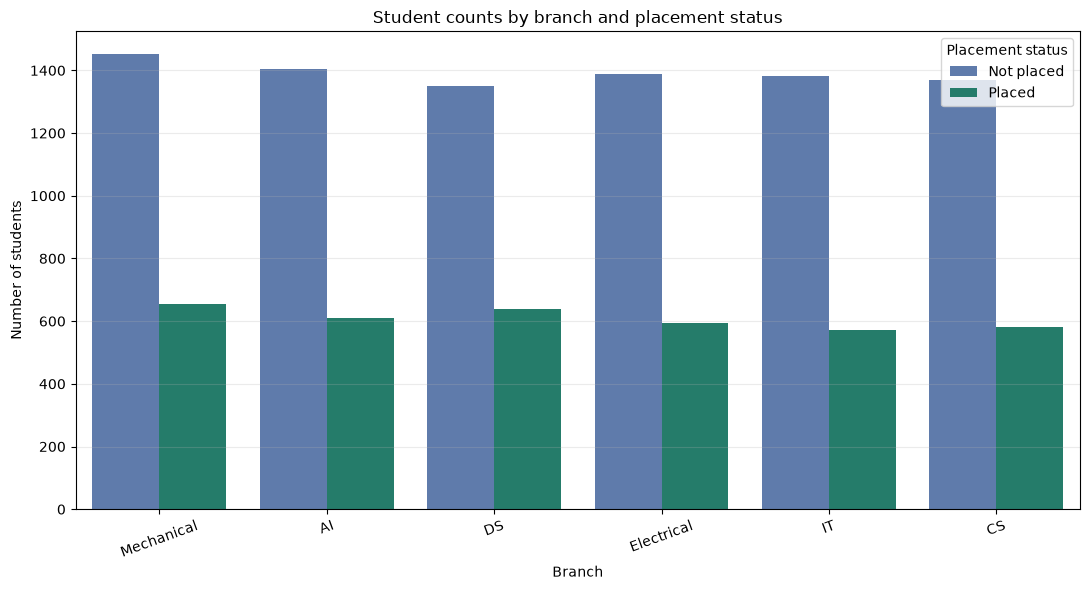

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

branch_order = df["branch"].value_counts().index.tolist()
placement_order = ["Not placed", "Placed"]

fig, ax = plt.subplots(figsize=(11, 6))
sns.countplot(
    data=df,
    x="branch",
    hue="placement_status",
    order=branch_order,
    hue_order=placement_order,
    palette={"Not placed": "#5277B8", "Placed": "#168A72"},
    ax=ax,
)
ax.set(title="Student counts by branch and placement status", xlabel="Branch", ylabel="Number of students")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Placement status")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 9. CGPA by degree and gender - Seaborn violin plot

**What it answers:** How are CGPA distributions shaped across degree and gender groups?

**How to read it:** Each violin shows where observations are concentrated; wider sections contain more students. The inner quartiles mark the median and middle half. This compares CGPA distributions, not placement outcomes.

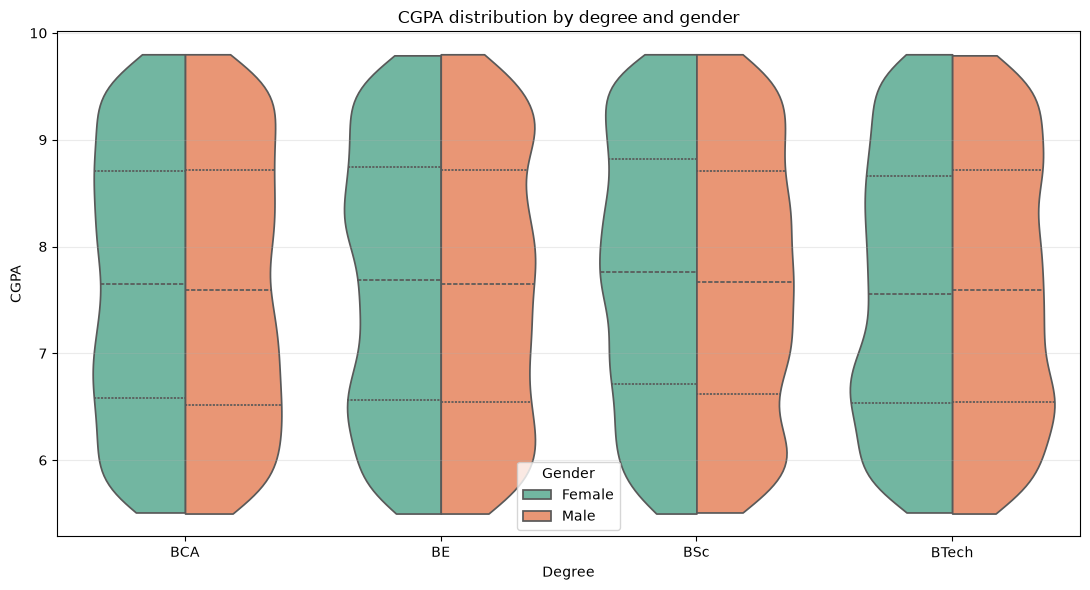

In [11]:
degree_order = sorted(df["degree"].dropna().unique())
fig, ax = plt.subplots(figsize=(11, 6))
sns.violinplot(
    data=df,
    x="degree",
    y="cgpa",
    hue="gender",
    order=degree_order,
    hue_order=sorted(df["gender"].dropna().unique()),
    split=True,
    inner="quart",
    cut=0,
    palette="Set2",
    ax=ax,
)
ax.set(title="CGPA distribution by degree and gender", xlabel="Degree", ylabel="CGPA")
ax.legend(title="Gender")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 10. Student measure correlations - Seaborn heatmap

**What it answers:** Which academic and skill measures tend to move together in this dataset?

**How to read it:** Correlation values range from -1 to +1. Values near +1 indicate a stronger positive linear association; values near -1 indicate a stronger negative linear association; values near 0 indicate a weaker linear association. Correlation does not prove cause and effect. Placement and package are omitted so zero package values for unplaced students do not distort this comparison.

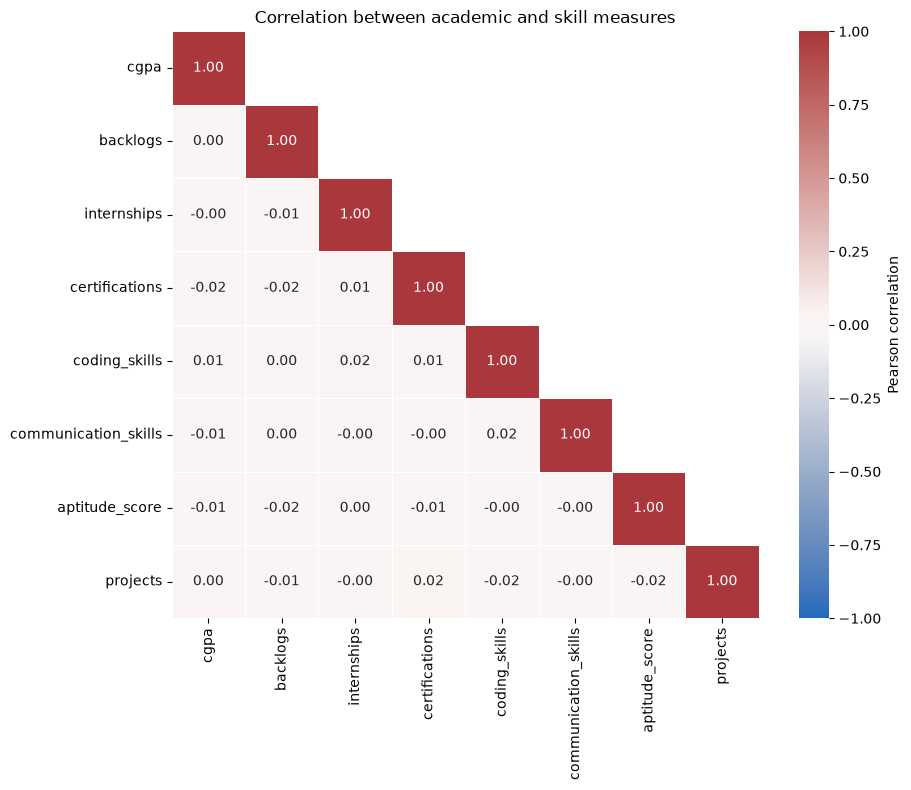

In [12]:
measure_columns = [
    "cgpa", "backlogs", "internships", "certifications", "coding_skills",
    "communication_skills", "aptitude_score", "projects",
]
measure_corr = df[measure_columns].corr()
upper_triangle = np.triu(np.ones_like(measure_corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    measure_corr,
    mask=upper_triangle,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set(title="Correlation between academic and skill measures")
fig.tight_layout()
plt.show()

## 11. Skill scores by placement status - Matplotlib

**What it answers:** How do coding and communication scores compare for placed and not-placed students?

**How to read it:** Each marker is one student from a reproducible sample; the x-axis is coding skill and the y-axis is communication skill. Colors show placement status. Overlap is expected, and this plot alone cannot explain or predict placement.

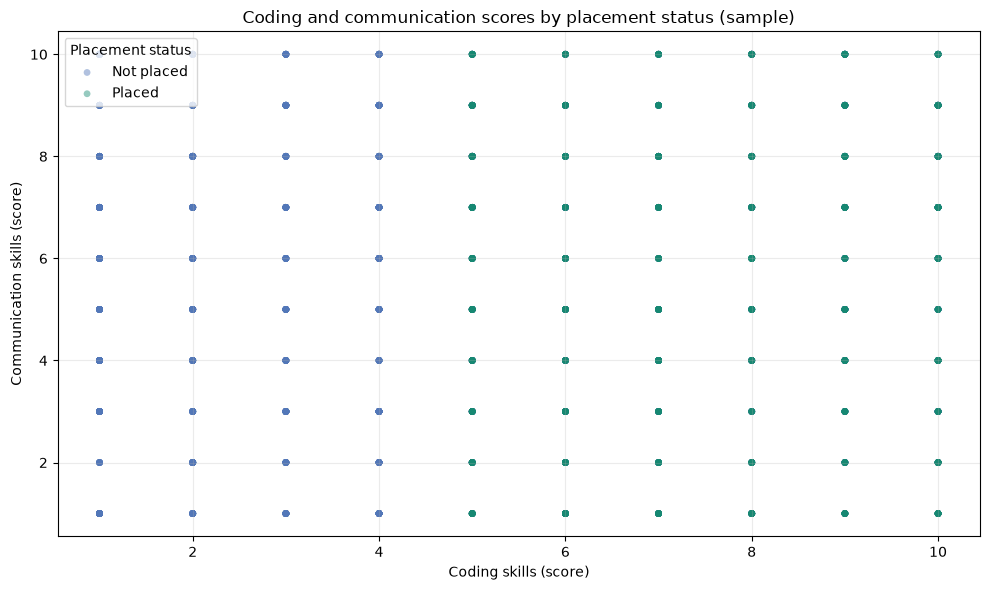

In [13]:
skill_sample = df.sample(n=min(2500, len(df)), random_state=42)
colors = {"Not placed": "#5277B8", "Placed": "#168A72"}
fig, ax = plt.subplots(figsize=(10, 6))
for status in placement_order:
    group = skill_sample.loc[skill_sample["placement_status"].eq(status)]
    ax.scatter(
        group["coding_skills"],
        group["communication_skills"],
        label=status,
        color=colors[status],
        alpha=0.45,
        s=24,
        edgecolors="none",
    )
ax.set(
    title="Coding and communication scores by placement status (sample)",
    xlabel="Coding skills (score)",
    ylabel="Communication skills (score)",
)
ax.legend(title="Placement status")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 12. Placement rate by degree and gender - interactive Plotly

**What it answers:** Are observed placement rates different across degree and gender groups?

**How to read it:** Bars show the share placed within each degree/gender group (not the raw count); hover shows the group size and placed-student count. Use the legend to hide or isolate a gender. Small differences are descriptive and not evidence of unfairness or causation.

In [14]:
degree_gender = (
    df.groupby(["degree", "gender"], as_index=False, observed=True)
    .agg(students=("student_id", "size"), placed_students=("placed", "sum"))
)
degree_gender["placement_rate"] = degree_gender["placed_students"] / degree_gender["students"]

fig = px.bar(
    degree_gender,
    x="degree",
    y="placement_rate",
    color="gender",
    barmode="group",
    category_orders={"degree": degree_order},
    custom_data=["students", "placed_students"],
    title="Placement rate by degree and gender",
    labels={"degree": "Degree", "placement_rate": "Placement rate", "gender": "Gender"},
)
fig.update_traces(
    hovertemplate=(
        "Degree: %{x}<br>Gender: %{fullData.name}<br>Placement rate: %{y:.1%}"
        "<br>Placed students: %{customdata[1]:,} of %{customdata[0]:,}<extra></extra>"
    )
)
fig.update_layout(template="plotly_white", yaxis_tickformat=".0%", yaxis_range=[0, 1])
fig.show()

## 13. Coding and communication scores - interactive Plotly

**What it answers:** How do the two skill scores relate, and how are students distributed across placement status?

**How to read it:** Each point is one student. Hover for student and category details. Click legend items to filter placement groups; zoom into dense areas to inspect overlap. The chart shows association only, not whether one score causes placement.

In [15]:
fig = px.scatter(
    df,
    x="coding_skills",
    y="communication_skills",
    color="placement_status",
    color_discrete_map={"Not placed": "#5277B8", "Placed": "#168A72"},
    render_mode="webgl",
    opacity=0.55,
    custom_data=["student_id", "gender", "degree", "branch", "aptitude_score"],
    title="Coding and communication scores by placement status",
    labels={
        "coding_skills": "Coding skills (score)",
        "communication_skills": "Communication skills (score)",
        "placement_status": "Placement status",
    },
)
fig.update_traces(
    marker={"size": 7},
    hovertemplate=(
        "Student ID: %{customdata[0]}<br>Coding score: %{x}<br>Communication score: %{y}"
        "<br>Status: %{fullData.name}<br>Gender: %{customdata[1]}"
        "<br>Degree: %{customdata[2]}<br>Branch: %{customdata[3]}"
        "<br>Aptitude score: %{customdata[4]}<extra></extra>"
    ),
)
fig.update_layout(template="plotly_white")
fig.show()

## 14. Package by degree - interactive Plotly violin plot

**What it answers:** How do salary package distributions compare across degrees for placed students?

**How to read it:** The violin width shows where packages are concentrated, the box shows the interquartile range, and the line shows the median. Hover over points and use the legend to compare groups. Unplaced students are excluded because their zero package is not an offer.

In [16]:
fig = px.violin(
    placed_df,
    x="degree",
    y="package_lpa",
    color="degree",
    category_orders={"degree": degree_order},
    box=True,
    points="outliers",
    hover_data={"student_id": True, "gender": True, "company_type": True, "branch": True},
    title="Package distribution by degree (placed students only)",
    labels={"degree": "Degree", "package_lpa": "Package (LPA)"},
)
fig.update_layout(template="plotly_white", showlegend=False)
fig.show()

## 15. Do placement rates differ by branch and gender?

**Question:** Within each branch, how do observed placement rates compare across genders?

**How to read it:** Each grouped bar is a placement rate, not a student count. Hover for the group size and number placed; interpret small groups cautiously.

## 16. How do projects and certifications relate to placement?

**Question:** How do placement rates vary across project and certification counts, and do the patterns differ by gender?

**How to read it:** Each bubble represents a project/certification combination for one gender. Color encodes the placement rate and bubble size encodes the number of students. Hover for exact group counts. These are associations, not evidence that projects or certifications cause placement.

## 17. How do packages compare across branches and company types?

**Question:** Among placed students, how does the median package vary by branch and employer type?

**How to read it:** Bars compare medians; hover for the number of placed students behind each value. Salary comparisons exclude students who were not placed.

In [7]:
from pathlib import Path

import pandas as pd
import plotly.express as px

if "df" not in globals() or "placed_df" not in globals():
    data_file = "Indian_Student_Placement_Dataset_2025_Cleaned.csv"
    search_folders = [Path.cwd(), *Path.cwd().parents]
    csv_path = next(
        (folder / data_file for folder in search_folders if (folder / data_file).is_file()),
        None,
    )
    if csv_path is None:
        raise FileNotFoundError(
            f"Could not find {data_file!r}. Place the cleaned CSV beside this notebook, "
            "or open the notebook from its project folder."
        )
    df = pd.read_csv(csv_path)
    required_columns = {
        "student_id", "gender", "branch", "projects", "certifications",
        "placed", "company_type", "package_lpa",
    }
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(f"The dataset is missing required columns: {sorted(missing_columns)}")
    if not df["placed"].isin([0, 1]).all():
        raise ValueError("The 'placed' column must contain only 0 (not placed) and 1 (placed).")
    placed_df = df.loc[df["placed"].eq(1)].copy()

branch_gender_summary = (
    df.groupby(["branch", "gender"], as_index=False, observed=True)
    .agg(students=("student_id", "size"), placed_students=("placed", "sum"))
)
branch_gender_summary["placement_rate"] = (
    branch_gender_summary["placed_students"] / branch_gender_summary["students"]
)
branch_category_order = sorted(df["branch"].dropna().unique())
gender_category_order = sorted(df["gender"].dropna().unique())

fig = px.bar(
    branch_gender_summary,
    x="branch",
    y="placement_rate",
    color="gender",
    barmode="group",
    category_orders={"branch": branch_category_order, "gender": gender_category_order},
    custom_data=["students", "placed_students"],
    title="Placement rate by branch and gender",
    labels={"branch": "Branch", "placement_rate": "Placement rate", "gender": "Gender"},
)
fig.update_traces(
    hovertemplate=(
        "Branch: %{x}<br>Gender: %{fullData.name}<br>Placement rate: %{y:.1%}"
        "<br>Placed students: %{customdata[1]:,} of %{customdata[0]:,}<extra></extra>"
    )
)
fig.update_layout(template="plotly_white", yaxis_tickformat=".0%", yaxis_range=[0, 1])
fig.show()

project_cert_summary = (
    df.groupby(["projects", "certifications", "gender"], as_index=False, observed=True)
    .agg(students=("student_id", "size"), placed_students=("placed", "sum"))
)
project_cert_summary["placement_rate"] = (
    project_cert_summary["placed_students"] / project_cert_summary["students"]
)

fig = px.scatter(
    project_cert_summary,
    x="projects",
    y="certifications",
    color="placement_rate",
    size="students",
    symbol="gender",
    size_max=32,
    color_continuous_scale="Viridis",
    hover_data={
        "gender": True,
        "students": True,
        "placed_students": True,
        "placement_rate": ":.1%",
    },
    title="Placement rate by project and certification counts",
    labels={
        "projects": "Number of projects",
        "certifications": "Number of certifications",
        "placement_rate": "Placement rate",
        "gender": "Gender",
        "students": "Students",
        "placed_students": "Placed students",
    },
)
fig.update_layout(template="plotly_white", xaxis_dtick=1, yaxis_dtick=1)
fig.show()

company_category_order = ["Product", "Service", "Startup"]
package_by_branch = (
    placed_df.loc[placed_df["company_type"].isin(company_category_order)]
    .groupby(["branch", "company_type"], as_index=False, observed=True)
    .agg(students=("student_id", "size"), median_package_lpa=("package_lpa", "median"))
)

fig = px.bar(
    package_by_branch,
    x="branch",
    y="median_package_lpa",
    color="company_type",
    barmode="group",
    category_orders={"branch": branch_category_order, "company_type": company_category_order},
    hover_data={"students": True, "median_package_lpa": ":.2f"},
    title="Median package by branch and company type (placed students only)",
    labels={
        "branch": "Branch",
        "median_package_lpa": "Median package (LPA)",
        "company_type": "Company type",
        "students": "Placed students",
    },
)
fig.update_layout(template="plotly_white")
fig.show()

## Reading the results responsibly

- These charts describe the students in this dataset; they do not establish cause and effect.
- Placement rates use each group's total student count as the denominator. Salary plots include placed students only.
- Hover values and subgroup sizes should be checked before interpreting a visual difference.
- Do not infer that a pattern applies to all colleges, years, students, or employers without checking how the dataset was collected.

**Suggested next step:** choose a pattern that interests you, filter the legend or zoom into the chart, then compare the underlying group counts before drawing a conclusion.